In [1]:
import pandas as pd
import numpy as np

## Corpus text analysis

In [3]:
from driver import clean_text

corpus = pd.read_excel("Data/corpus.xlsx")
corpus["text_content"] = corpus["text_content"].apply(lambda x: clean_text(x))
corpus.head()

,doc_id,url,html_content,text_content,scraping_source
0,d0,https://wwftravel.it/blog/viaggi/india-natura-...,"<body><p>""\n</p>\n<a class=""skip-link screen-r...",Vai al contenuto Home Blog Viaggi India natura...,manual-scraped
1,d1,https://www.terreincognitemagazine.it/natura-s...,"<body class=""single single-post postid-2526 si...",Homepage > CULTURA > MOSTRE > Natura selvaggia...,auto-scraped
2,d2,https://www.storicang.it/a/civilta-dellindo-i-...,"<body><p>""\n</p><div aria-hidden=""true"" class=...",La prospera civiltà della valle dell'Indo creb...,manual-scraped
3,d3,https://www.focusjunior.it/scuola/storia/chi-s...,"<body><div id=""fb-root""></div>\n<noscript></no...",FocusJunior.it Scuola Storia Chi sono gli Indi...,auto-scraped
4,d4,https://www.focusjunior.it/comportamento/feste...,"<body><div id=""fb-root""></div>\n<noscript></no...",FocusJunior.it Comportamento Feste Festa della...,auto-scraped


In [4]:
from driver import get_text_stats

text_stat_results = get_text_stats(corpus, "text_content")

corpus["content_len"] = text_stat_results["content_len"]
corpus["mean_aoa"] = text_stat_results["mean_aoa"]
corpus["mean_conc"] = text_stat_results["mean_conc"]
corpus["gulpease_index"] = text_stat_results["gulpease_index"]

  0%|          | 0/221 [00:00<?, ?it/s]

c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [5]:
corpus.to_excel("Data/analysed_corpus.xlsx", index=False)

In [6]:
corpus.head()

,doc_id,url,html_content,text_content,scraping_source,content_len,mean_aoa,mean_conc,gulpease_index
0,d0,https://wwftravel.it/blog/viaggi/india-natura-...,"<body><p>""\n</p>\n<a class=""skip-link screen-r...",Vai al contenuto Home Blog Viaggi India natura...,manual-scraped,1389,5.314087,6.307500,51.666813
1,d1,https://www.terreincognitemagazine.it/natura-s...,"<body class=""single single-post postid-2526 si...",Homepage > CULTURA > MOSTRE > Natura selvaggia...,auto-scraped,1644,5.600471,5.939623,44.195174
2,d2,https://www.storicang.it/a/civilta-dellindo-i-...,"<body><p>""\n</p><div aria-hidden=""true"" class=...",La prospera civiltà della valle dell'Indo creb...,manual-scraped,1635,5.520000,6.553509,43.365193
3,d3,https://www.focusjunior.it/scuola/storia/chi-s...,"<body><div id=""fb-root""></div>\n<noscript></no...",FocusJunior.it Scuola Storia Chi sono gli Indi...,auto-scraped,1724,5.302264,5.982432,47.746429
4,d4,https://www.focusjunior.it/comportamento/feste...,"<body><div id=""fb-root""></div>\n<noscript></no...",FocusJunior.it Comportamento Feste Festa della...,auto-scraped,1140,4.143614,6.745545,52.684927


## Information distillation analysis

In [ ]:
corpus_df = pd.read_excel("Data/analysed_corpus.xlsx")

explored_pages_df = pd.read_csv("Data/explored_pages.csv")
explored_pages_df["timestamp"] = pd.to_datetime(explored_pages_df["timestamp"])
explored_pages_df["click_time"] = pd.to_datetime(explored_pages_df["click_time"])

information_distillation_df = pd.read_csv("Data/information_distillation_df.csv")
information_distillation_df["timestamp"] = pd.to_datetime(information_distillation_df["timestamp"])
information_distillation_df["answer_time"] = pd.to_datetime(information_distillation_df["answer_time"])

# results_navigation = pd.read_csv("Data/results_navigation.csv")

In [57]:
explored_pages_df.head()

,uid,topic_number,url,exploreType,viewDurationInSeconds,timestamp,click_time,serp_id,click_rank
0,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageOpened,NaN,2026-05-19 14:51:44.064,2026-05-19 14:51:43.444,serp1,1
1,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageClosed,76.920,2026-05-19 14:53:00.984,2026-05-19 14:51:43.444,serp1,1
2,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageOpened,NaN,2026-05-19 14:53:20.022,2026-05-19 14:53:19.408,serp1,1
3,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageClosed,179.125,2026-05-19 14:56:19.147,2026-05-19 14:53:19.408,serp1,1
4,1,g3t2,https://it.gov-civ-guarda.pt/flag-india,webpageOpened,NaN,2026-05-19 15:02:49.238,2026-05-19 15:02:48.776,serp2,1


In [8]:
information_distillation_df.head()

,uid,topic_number,query,url,rank,timestamp,serp_id,relevance_score,answer,answer_time,answer_previously,change_from_prev_ans,num_answer_matches,matched_keywords,answer_match_ratio,effective_distillation
0,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,2026-05-19 14:51:43.444,serp1,1,NaN,NaT,NaN,[],0,[],0.0,0
1,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,2026-05-19 14:53:19.408,serp1,1,Rinoceronte tigre Leone stambecco cervo,2026-05-19 14:56:16.157,NaN,"['stambecco', 'cervo', 'rinoceronte', 'tigre',...",4,"['tigre', 'rinoceronte', 'leone', 'cervo']",0.8,1
2,1,g3t2,Quale è il nome del simbolo al centro della ba...,https://it.gov-civ-guarda.pt/flag-india,1,2026-05-19 15:02:48.776,serp2,1,Il simbolo della bandiera rappresenta una ruota,2026-05-19 15:06:16.071,NaN,"['il', 'simbolo', 'della', 'bandiera', 'rappre...",1,['ruota'],0.5,1
3,1,g3t1,Fiume sacro degli indiani,https://www.consciousjourneys.com/it/approfond...,2,2026-05-19 15:08:58.405,serp3,1,Il fiume gange,2026-05-19 15:10:08.259,NaN,"['il', 'fiume', 'gange']",1,['gange'],1.0,1
4,2,g3t3,Quali sono i 5 animali tipici dall'India,https://wwftravel.it/blog/viaggi/india-natura-...,1,2026-05-19 14:52:53.759,serp5,1,"Tigre,leone,rinoceronte,barasingha,blackbuck.",2026-05-19 14:58:05.034,NaN,"['tigre', ',', 'leone', ',', 'rinoceronte', ',...",5,"['tigre', 'rinoceronte', 'leone', 'barasingha'...",1.0,1


In [5]:
len(information_distillation_df.loc[information_distillation_df["effective_distillation"]==1]), len(information_distillation_df)

(93, 166)

In [6]:
explored_pages_df.head()

,uid,topic_number,url,exploreType,viewDurationInSeconds,timestamp,click_time
0,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageOpened,NaN,2026-05-19 14:51:44.064,2026-05-19 14:51:43.444
1,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageClosed,76.920,2026-05-19 14:53:00.984,2026-05-19 14:51:43.444
2,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageOpened,NaN,2026-05-19 14:53:20.022,2026-05-19 14:53:19.408
3,1,g3t3,https://wwftravel.it/blog/viaggi/india-natura-...,webpageClosed,179.125,2026-05-19 14:56:19.147,2026-05-19 14:53:19.408
4,1,g3t2,https://it.gov-civ-guarda.pt/flag-india,webpageOpened,NaN,2026-05-19 15:02:49.238,2026-05-19 15:02:48.776


In [9]:
corpus_df.head()

,doc_id,url,html_content,text_content,scraping_source,content_len,mean_aoa,mean_conc,gulpease_index
0,d0,https://wwftravel.it/blog/viaggi/india-natura-...,"<body><p>""\n</p>\n<a class=""skip-link screen-r...",Vai al contenuto Home Blog Viaggi India natura...,manual-scraped,1389,5.314087,6.307500,51.666813
1,d1,https://www.terreincognitemagazine.it/natura-s...,"<body class=""single single-post postid-2526 si...",Homepage > CULTURA > MOSTRE > Natura selvaggia...,auto-scraped,1644,5.600471,5.939623,44.195174
2,d2,https://www.storicang.it/a/civilta-dellindo-i-...,"<body><p>""\n</p><div aria-hidden=""true"" class=...",La prospera civiltà della valle dell'Indo creb...,manual-scraped,1635,5.520000,6.553509,43.365193
3,d3,https://www.focusjunior.it/scuola/storia/chi-s...,"<body><div id=""fb-root""></div>\n<noscript></no...",FocusJunior.it Scuola Storia Chi sono gli Indi...,auto-scraped,1724,5.302264,5.982432,47.746429
4,d4,https://www.focusjunior.it/comportamento/feste...,"<body><div id=""fb-root""></div>\n<noscript></no...",FocusJunior.it Comportamento Feste Festa della...,auto-scraped,1140,4.143614,6.745545,52.684927


In [62]:
# mean_rel_time = [] # average time spent on relevant resources
# mean_irrel_time = [] # average time spent on irrelevant resources
# rel_time_total_time_ratio = [] # proportion of total dwell time that was spent on relevant results 
# num_clicks = []
# num_unique_pages = []
# mean_ratio_results_explored_per_serp = [] # average proportion of resources explored in a SERP
# num_serps = []
# mean_click_depth = [] # what is the lowest ranked result user clicks on average

page_dwell_time = [] # time spent on the clicked resource before entering an answer or going back
avg_concreteness = []
avg_gulpease_index = []
avg_aoa = []
avg_content_length = []

for _, row in information_distillation_df.iterrows():

    uid = row["uid"]
    topic_num = row["topic_number"]
    answer_time = row["answer_time"]
    click_time = row["timestamp"]
    explored_page = explored_pages_df.loc[(explored_pages_df["uid"]==uid) & (explored_pages_df["exploreType"]=="webpageClosed") & (explored_pages_df["click_time"]==click_time)] # get the click instance
    if pd.isna(answer_time): # user did not open the answer box
        dwell_time = explored_page["viewDurationInSeconds"].values[0] 
    else:
        dwell_time = (answer_time - click_time).total_seconds() # time spent on the clicked resource before entering an answer
        if dwell_time > explored_page["viewDurationInSeconds"].values[0]: # child went back before entering an answer
            dwell_time = explored_page["viewDurationInSeconds"].values[0]

    if pd.isna(click_time):
        print("Row from click dataframe has an instance with no click time??")
        print(row)
        break

    url = row["url"]
    corpus_row = corpus_df.loc[corpus_df["url"]==url]

    page_dwell_time.append(dwell_time)
    avg_concreteness.append(corpus_row["mean_conc"].values[0])
    avg_gulpease_index.append(corpus_row["gulpease_index"].values[0])
    avg_aoa.append(corpus_row["mean_aoa"].values[0])
    avg_content_length.append(corpus_row["content_len"].values[0])

information_distillation_df["page_dwell_time"] = page_dwell_time
information_distillation_df["avg_concreteness"] = avg_concreteness
information_distillation_df["avg_gulpease_index"] = avg_gulpease_index 
information_distillation_df["avg_aoa"] = avg_aoa 
information_distillation_df["avg_content_length"] = avg_content_length
            

In [63]:
information_distillation_df.to_csv("Data/information_distillation_df.csv", index=False, encoding="utf8")
information_distillation_df.head()

,uid,topic_number,query,url,rank,timestamp,serp_id,relevance_score,answer,answer_time,...,num_answer_matches,matched_keywords,answer_match_ratio,effective_distillation,page_dwell_time,avg_concreteness,avg_gulpease_index,avg_aoa,avg_content_length,resource_rank
0,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,2026-05-19 14:51:43.444,serp1,1,NaN,NaT,...,0,[],0.0,0,76.920,6.307500,51.666813,5.314087,1389,1
1,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,2026-05-19 14:53:19.408,serp1,1,Rinoceronte tigre Leone stambecco cervo,2026-05-19 14:56:16.157,...,4,"['tigre', 'rinoceronte', 'leone', 'cervo']",0.8,1,176.749,6.307500,51.666813,5.314087,1389,1
2,1,g3t2,Quale è il nome del simbolo al centro della ba...,https://it.gov-civ-guarda.pt/flag-india,1,2026-05-19 15:02:48.776,serp2,1,Il simbolo della bandiera rappresenta una ruota,2026-05-19 15:06:16.071,...,1,['ruota'],0.5,1,207.295,6.177326,43.901500,5.521524,1116,1
3,1,g3t1,Fiume sacro degli indiani,https://www.consciousjourneys.com/it/approfond...,2,2026-05-19 15:08:58.405,serp3,1,Il fiume gange,2026-05-19 15:10:08.259,...,1,['gange'],1.0,1,36.112,6.622689,49.490058,5.207799,2037,2
4,2,g3t3,Quali sono i 5 animali tipici dall'India,https://wwftravel.it/blog/viaggi/india-natura-...,1,2026-05-19 14:52:53.759,serp5,1,"Tigre,leone,rinoceronte,barasingha,blackbuck.",2026-05-19 14:58:05.034,...,5,"['tigre', 'rinoceronte', 'leone', 'barasingha'...",1.0,1,311.275,6.307500,51.666813,5.314087,1389,1


## Visualisation

In [ ]:
import pandas as pd

information_distillation_df = pd.read_csv("Data/information_distillation_df.csv")
categories = ["page_dwell_time", "rank", "avg_content_length", "avg_gulpease_index", "avg_aoa", "avg_concreteness"]

In [2]:
print(len(categories))

6


In [3]:
len(information_distillation_df.loc[information_distillation_df["effective_distillation"]==1]), len(information_distillation_df)

(93, 166)

### RQ1

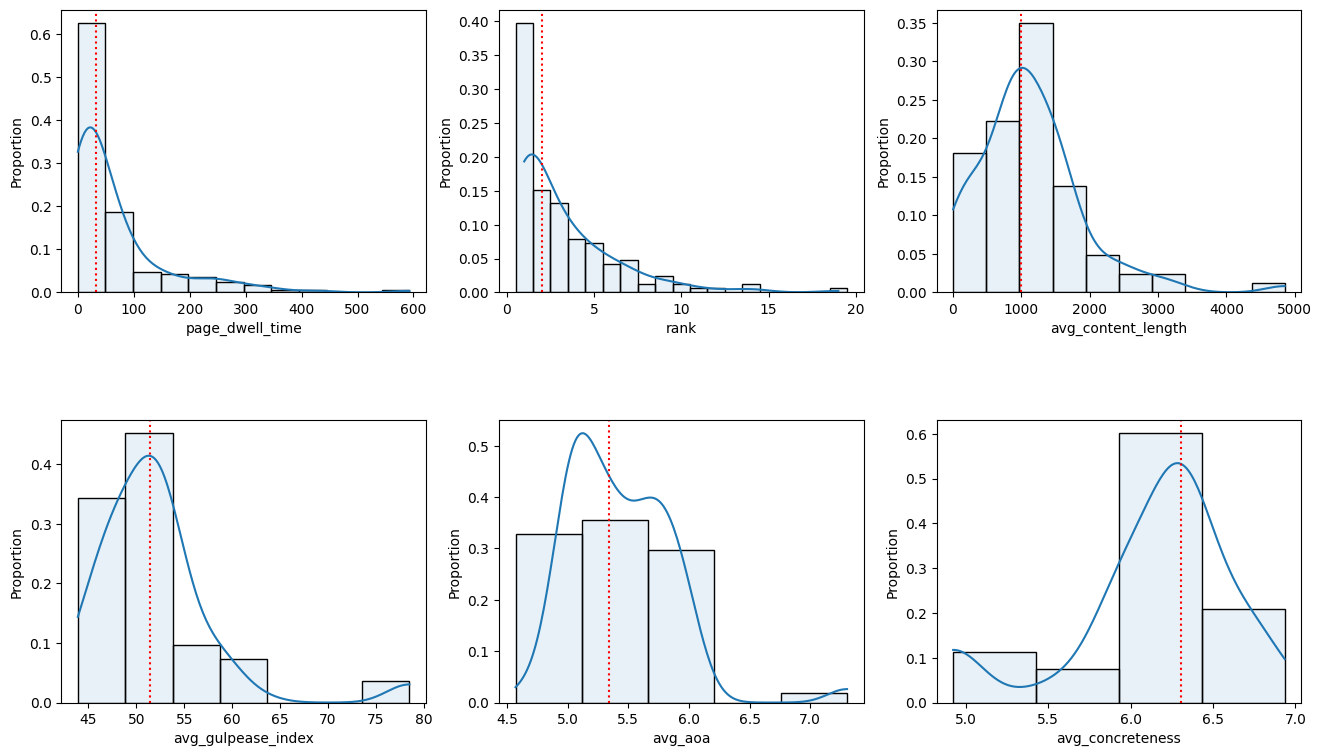

,category,mean,std_dev,max,min,median,modes
0,page_dwell_time,65.594633,90.957095,592.756000,0.171000,32.051000,"[0.171, 0.667, 1.392, 1.397, 1.761, 1.771, 1.7..."
1,rank,3.216867,2.982975,19.000000,1.000000,2.000000,[1]
2,avg_content_length,1133.927711,790.252315,4854.000000,4.000000,998.000000,[204]
3,avg_gulpease_index,52.001765,6.499591,78.500000,43.901500,51.432797,[47.89188555347093]
4,avg_aoa,5.433324,0.434768,7.303167,4.569362,5.337385,[5.8125]
5,avg_concreteness,6.118093,0.508185,6.934848,4.922727,6.307500,[4.922727272727273]


In [4]:
from driver import get_descriptive_stats

binwidth_map = {
    "page_dwell_time": 50,
    "rank": 1,
    "avg_aoa": 0.5,
    "avg_gulpease_index": 5,
    "avg_content_length": 500,
    "avg_concreteness": 0.5
}

desc_stats = get_descriptive_stats(df=information_distillation_df, search_stage="information_distillation", categories=categories, ncols=3, nrows=2, binwidth_map=binwidth_map)
desc_stats

In [50]:
len(information_distillation_df.loc[information_distillation_df["page_dwell_time"]<100])/len(information_distillation_df[~pd.isna(information_distillation_df["page_dwell_time"])])

0.8132530120481928

In [11]:
len(information_distillation_df.loc[information_distillation_df["rank"]<=5])/len(information_distillation_df[~pd.isna(information_distillation_df["rank"])])

0.8313253012048193

In [30]:
df = pd.DataFrame(information_distillation_df[["uid", "topic_number"]].value_counts().to_frame(name="count").reset_index())
df.sort_values(by="uid", inplace=True)
df

,uid,topic_number,count
19,1,g3t3,2
32,1,g3t2,1
33,1,g3t1,1
30,2,g3t3,1
29,2,g3t2,1
31,2,g3t1,1
20,3,g3t2,2
27,3,g3t3,1
26,4,g3t3,2
28,4,g3t1,1


In [35]:
len(information_distillation_df.loc[information_distillation_df["avg_gulpease_index"]<60])/len(information_distillation_df)

0.9518072289156626

In [42]:
len(information_distillation_df.loc[information_distillation_df["avg_concreteness"]>5.5])/len(information_distillation_df)

0.8373493975903614

In [15]:
len(information_distillation_df.loc[information_distillation_df["avg_content_length"]<=2000])/len(information_distillation_df)

0.891566265060241

### RQ2

In [12]:
from driver import get_significance

desc_stats_df, sig_test_results = get_significance(df=information_distillation_df, effective_label="effective_distillation", search_stage="information_distillation", categories=categories)
sig_test_results

,search_stage,characteristic,test_statistic,pval,significant
0,information_distillation,page_dwell_time,-25.967000,0.0042,True
1,information_distillation,rank,0.000000,1.0000,False
2,information_distillation,avg_content_length,3.000000,0.5986,False
3,information_distillation,avg_gulpease_index,-2.036311,0.0020,True
4,information_distillation,avg_aoa,0.382445,0.0002,True
5,information_distillation,avg_concreteness,-0.341837,0.0002,True


In [13]:
desc_stats_df

,search_stage,characteristic,ineffective_median,ineffective_MAD,effective_median,effective_MAD
0,information_distillation,page_dwell_time,19.370000,13.440000,45.337000,35.188000
1,information_distillation,rank,2.000000,1.000000,2.000000,1.000000
2,information_distillation,avg_content_length,998.000000,323.000000,995.000000,403.000000
3,information_distillation,avg_gulpease_index,50.537640,1.874002,52.573950,3.076957
4,information_distillation,avg_aoa,5.590244,0.276157,5.207799,0.204370
5,information_distillation,avg_concreteness,5.978571,0.328929,6.320408,0.148980


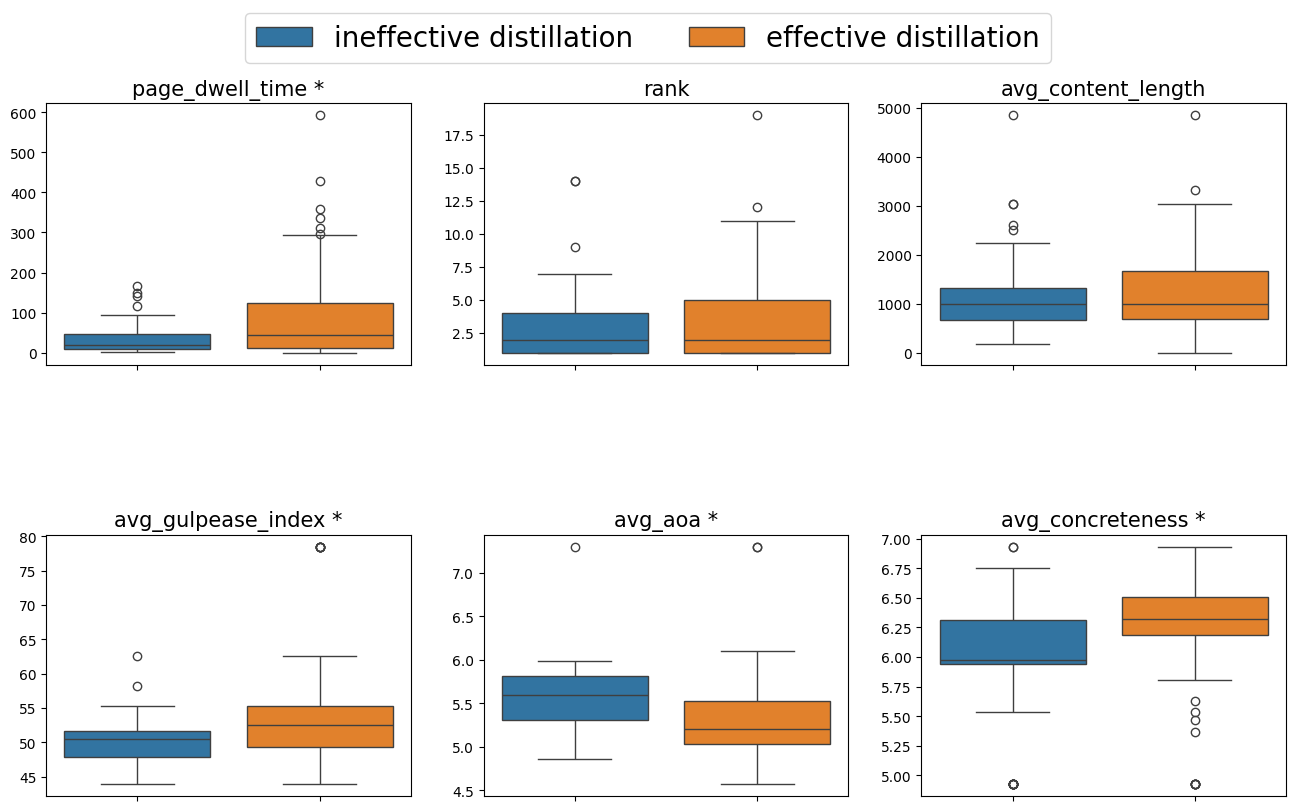

In [14]:
from driver import get_boxplots

get_boxplots(information_distillation_df, "information_distillation", categories, "effective_distillation", artefact="distillation", n_cols=3, n_rows=2, stats_df=sig_test_results)

In [ ]:
# from scipy.stats import spearmanr

# for category in categories:
#     res = spearmanr(information_distillation["answer_match_ratio"], information_distillation[category], nan_policy="omit")
#     print(f"Category: {category}; \tcoefficient: {res.statistic}; \tpval: {res.pvalue}")

Category: mean_rel_time; 	coefficient: 0.38456777750068283; 	pval: 0.013043357026280908
Category: mean_irrel_time; 	coefficient: 0.42778663099777736; 	pval: 0.0765743238863664
Category: rel_time_total_time_ratio; 	coefficient: -0.17892673917716623; 	pval: 0.2509599235095695
Category: avg_content_length; 	coefficient: 0.17560822143691956; 	pval: 0.2600013965015384
Category: avg_gulpease_index; 	coefficient: 0.2965665814308143; 	pval: 0.05347018043924833
Category: avg_aoa; 	coefficient: 0.0657380540648458; 	pval: 0.6869360616731846
Category: avg_concreteness; 	coefficient: 0.1641184522170633; 	pval: 0.3115645827085978
